# Vamana（单层近邻图搜索算法）

## 1. Vamana 的灵感来源：单层地图上的近路与远路

先考虑一个问题：不用分层可导航小世界图（Hierarchical Navigable Small World，HNSW）的多层结构，只维护一张近邻图，能否同时保留局部近路和跨区域导航能力？

Vamana 分两步工作：先用 **贪心搜索（`GreedySearch`）** 从入口出发，沿图中的连接逐步访问更接近目标的点，得到一批“可能是近邻、值得继续检查”的点；建图时再用 **鲁棒裁剪（`RobustPrune`）** 删除作用重复的连接，只留下通往近处或不同方向的邻居。这样，一张单层有向图既能在目标附近细找，也能借助较长的连接跳到其他区域。

### 1.1 HNSW 的多层地图

想象一座城市里有很多地点，每个地点对应一个向量，道路对应向量之间的邻接关系。HNSW 会维护多层地图：顶层地点少、道路稀疏，适合跨城区跳跃；底层地点多、道路密集，适合在街区内精细移动。搜索时从高层进入，逐层下降。

这是一种很自然的导航策略，但建图和查询都需要处理层级、每个节点的多层邻居，以及不同层的入口状态。

### 1.2 Vamana 的单层地图

Vamana 只维护一张单层有向图，通过邻居筛选保留两类道路：

- **局部道路**：通往真正近邻，便于在目标附近收敛；
- **较长但有导航价值的道路**：帮助搜索从一个区域跳到另一个区域，避免在局部道路里绕圈。

关键在于鲁棒裁剪：它不只比较“谁离当前点最近”，还会判断两条连接的作用是否重复。如果经过已经选中的邻居也能方便地到达另一个点，就可以不再保留直达那个点的连接。因此，一张单层地图也能同时留下街区小路和跨区道路。

### 1.3 两者的共同点

HNSW 与 Vamana 都从一个入口点出发，不断检查看起来更接近目标的点。为了避免检查全部数据，它们只保留一定数量的待检查点。二者的主要差别在于地图怎样分层、连接怎样取舍。

## 2. 算法原理分步详解

Vamana 是一种基于 **单层可导航近邻图（navigable graph，指可以沿着点之间的连接逐步接近查询目标的图）** 的近似最近邻搜索算法。它先为每个向量保留一组有导航价值的邻居，再让查询沿着图边逐步逼近目标。

其核心思想是：

> **只保留一定数量的待检查点来控制搜索范围，再删除作用重复的连接，同时留下附近连接和通往不同方向的连接。**

算法可以拆成搜索、裁剪、建图和查询四个部分。

---

### 2.1 图结构与入口点

给定数据集 `X = {x₁, x₂, ..., xₙ}`，Vamana 图通常是单层有向图 `G=(V,E)`。每个节点最多有 `R` 条出边，出边指向可以继续探索的节点。边的方向允许不对称：`u → v` 存在，不代表 `v → u` 一定存在。

搜索需要一个入口点。常见选择是**中心代表点（medoid，即到其他数据点的距离总和最小的数据点）**，也可以使用近似中心或构建阶段维护的入口。入口不是查询结果，它只是进入地图的起点；入口选得合理，搜索更容易快速进入目标区域。

### 2.2 贪心搜索（`GreedySearch`）：逐步找出值得检查的点

给定要查询的向量 `q`、入口 `s` 和列表容量上限 `L`，搜索过程如下：

1. 把入口放入待检查列表，并按它与查询向量的距离 `d(q, ·)` 排序；
2. 从列表中取出离查询向量最近、而且还没有检查过邻居的点；
3. 查看这个点连接了哪些邻居，把新发现的点加入待检查列表；
4. 待检查列表最多保留离查询向量较近的 `L` 个点，再从中选择下一个；
5. 当待检查列表中不再有尚未检查邻居的点时停止。算法返回最终保留的点、所有已经检查过邻居的点，以及检查顺序。

`L` 只限制“当前列表最多放多少个点”，不限制整个搜索一共会看到或检查多少个点。列表中同时有已经检查过的点和还没检查的点。某个还没检查的点即使暂时因列表已满而被移除，之后从别的连接再次遇到它时，仍可重新放回列表。增大 `L` 通常能保留更多搜索方向，但也会检查更多点。建图和查询都能使用这个过程，只是两者通常采用不同的 `L`。

可以把它理解成导航员手里的一张“待核实地址清单”：每走到一个地址，就把它附近的新地址加入清单，再优先核实离目的地更近的地址。

---

### 2.3 鲁棒裁剪（`RobustPrune`）：删除作用重复的连接

对当前点 `p`，先收集一批可能与它相连的点，记为集合 `C`，然后最多留下 `R` 个邻居。最简单的做法是只选离 `p` 最近的 `R` 个点，但这些点可能全在同一个方向，无法帮助搜索跳到其他区域。

鲁棒裁剪会优先留下最近的点，再删除作用与它重复的连接。具体步骤如下：

1. 从 `C` 中取出离 `p` 最近的点 `p*`，将它加入结果；
2. 对其余点 `p'`，检查是否满足
   `α · d(p*, p') <= d(p, p')`；
3. 若满足，说明从 `p` 先到 `p*`，再到 `p'` 已经足够方便，直接连接 `p → p'` 的作用重复，可以删除。算法把这种情况称为“`p'` 被 `p*` 遮蔽”；
4. 不满足条件的点可能通向不同方向，仍留在 `C` 中，再从中选择下一个离 `p` 最近的点；
5. 直到 `C` 中没有点可选，或结果已经有 `R` 个邻居。

参数 `α` 的方向取决于这个不等式的写法。对本文的 `α · d(p*, p') <= d(p, p')`，增大 `α` 会让删除条件更难成立，待筛选的点更不容易因为“连接作用重复”而被删掉。出度还没有顶到 `R` 时，图里可能因此多留下一些边；出度已经顶满时，变的是哪些边被留下。边长和方向多样性取决于待筛选点的组成，不能看成随 `α` 单调增加。

**城市类比**：从地点 `p` 出发，先选最近的路口 `p*`。如果另一个路口 `p'` 从 `p*` 出发也很容易到达，那么再修一条 `p→p'` 的路价值不高；如果 `p'` 位于另一条街区方向，即使它更远，也可能是重要的转向点。

---

### 2.4 建图流程

建图可以拆成以下步骤：

1. **初始有限度图**：为每个节点随机连接少量其他节点，得到可探索的起点图；
2. **选择入口点**：用中心代表点（medoid）或其近似值作为 `s`；
3. **按随机顺序处理节点**：随机顺序减少输入顺序带来的偏置；
4. **为当前节点搜索**：从入口 `s` 执行贪心搜索（`GreedySearch`），保留搜索过程中所有已经检查过邻居的点，记为集合 `V`；
5. **合并并裁剪**：把集合 `V` 与当前已有邻居合并，去掉 `p` 自身，再调用鲁棒裁剪（`RobustPrune`）；
6. **补反向边**：若鲁棒裁剪保留了出边 `p → q`，可以尝试把 `p` 加入 `q` 的出邻居；
7. **反向边超限时再裁剪**：对超出 `R` 的节点重新执行裁剪。

经典 Vamana 构建会对所有节点处理两遍：第一遍用 `α=1`，第二遍用目标 `α>1`；论文观察到两遍构建能提升图质量。第二遍更不容易删边，会保留更多较长、方向不同的连接。本文实现只构建一轮。

反向边处理很重要。只建单向近邻边可能造成某些节点无法回到主图；但无条件添加反向边又会让出度失控，所以必须在补边后再次保持 `R` 上限。

---

### 2.5 查询流程

查询时不需要重新建图：

1. 从入口点 `s` 开始；
2. 用贪心搜索持续检查更接近查询向量的点，列表容量上限为 `L_search`；
3. 从最终搜索列表中选距离最小的 `k` 个返回。

`L_search` 是查询时最直接的速度—召回率旋钮。它表示查询阶段的搜索列表大小；当接口要求返回 `k` 个结果时，`L_search` 不能小于 `k`。它不是访问节点总数的硬上限。当图本身缺少关键连接时，扩大预算也只能缓解而不能完全修复建图问题。

### 2.6 参数怎么理解

| 参数 | 作用 | 增大后的常见收益 | 增大后的代价 |
| --- | --- | --- | --- |
| `R` | 每个节点的最大出度 | 更多局部与跨区道路，图更容易导航 | 内存、建图时间和每次扩展的邻居数增加 |
| `L_build` | 建图时贪心搜索的列表容量上限 | 建图时更可能看到有用的连接 | 需要计算更多距离 |
| `α` | 鲁棒裁剪删除重复连接的严格程度 | 在本文不等式下，增大它使删除更难触发；出度未满时可能多留边 | 出度仍受 `R` 截断。出度已满时改变的是边的取舍，边长和方向多样性不随 `α` 单调增加 |
| `L_search` | 查询时待检查列表的容量上限 | 可能检查更多点，召回率通常提高 | 查询延迟和距离计算增加 |

### 2.7 性能特点

- **单层导航**：不需要维护 HNSW 的随机层级，图结构更直接；
- **方向多样性**：鲁棒裁剪不只保留最近节点，也尽量避免邻居集中在同一方向；
- **速度—召回可调**：`L_search` 控制查询时最多保留多少个待检查点，`R` 和 `L_build` 控制图质量与建图成本；
- **适合系统组合**：Vamana 可以完全在内存中使用，也可以在更大的存储系统中先缩小需要检查的数据范围。

### 2.8 类比理解

| Vamana 概念 | 城市道路类比 | 作用 |
| --- | --- | --- |
| 入口点 | 导航的出发位置 | 进入整张地图 |
| 局部邻居 | 街区道路 | 在目标附近精细移动 |
| 较长导航边 | 跨区道路 | 跳出局部区域 |
| 贪心搜索（`GreedySearch`） | 不断更新待核实地址清单 | 找到更值得继续检查的点 |
| 鲁棒裁剪（`RobustPrune`） | 删除功能重复的道路 | 在道路数有限时保留不同方向的连接 |

**✅ 总结：Vamana 的核心思想**

> **在单层图上逐步检查更近的点，并删除作用重复的连接。**

## 3. Vamana 与 HNSW 对比

| 维度 | Vamana | HNSW |
| --- | --- | --- |
| 层级结构 | 单层有向图 | 多层图，底层通常最密 |
| 远距导航 | 由鲁棒裁剪保留部分较长、方向不同的连接 | 由高层稀疏图提供跨区域跳跃 |
| 邻居裁剪 | 以遮蔽关系和 `α` 控制方向多样性 | 按层使用邻居选择启发式与度数上限 |
| 建图时用于筛选连接的点 | 使用贪心搜索检查过的全部点 | 典型 HNSW 邻居选择主要围绕最终搜索列表 |
| 核心参数 | `R`、`L_build`、`α`、`L_search` | `M`、`ef_construction`、`ef_search`、层级规则 |
| 更新特点 | 通常批量建图；动态更新需要额外维护策略 | 支持逐步插入，但也需要维护多层连接 |
| 与固态硬盘（SSD）系统的关系 | 可纯内存运行，也可作为磁盘系统中缩小查找范围的基础 | 常见于内存，也可与其他存储方案组合 |

两者都能取得较高召回率，但成本分布不同。选择时需要一起考虑数据规模、更新方式、内存预算和存储层级。

## 4. Vamana 算法实现

🧠 Vamana 的 Python 实现

配套 Notebook：[src/ANN_alorithms/Vamana算法.ipynb](https://github.com/datawhalechina/easy-vectordb/blob/main/src/ANN_alorithms/Vamana算法.ipynb)。

`SimpleVamana` 使用二维或一般维度的 NumPy 数组，距离为欧氏距离，并返回所有检查过邻居的点及其检查顺序。

### 4.1 导入依赖


In [1]:
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass

import random
import warnings

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive")
plt.rcParams["font.sans-serif"] = ["Noto Sans CJK SC", "Hiragino Sans GB", "SimHei", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False



### 4.2 实现简化的 Vamana 类

下面的实现保留贪心搜索（`GreedySearch`）、鲁棒裁剪（`RobustPrune`）、建图和查询主线。它使用内存中的全精度 NumPy 数组，精确计算中心代表点，并简化初始图、构建轮次与反向边维护。


In [2]:
class SimpleVamana:
    def __init__(self, R=8, L_build=24, alpha=1.2, L_search=24, seed=7):
        if R < 1 or L_build < 1 or L_search < 1:
            raise ValueError("R、L_build 和 L_search 必须为正数")
        if alpha < 1:
            raise ValueError("alpha 必须大于或等于 1")
        self.R = int(R)
        self.L_build = int(L_build)
        self.alpha = float(alpha)
        self.L_search = int(L_search)
        self.rng = random.Random(seed)
        self.graph = []
        self.entry = None
        self.X = None

    def distance(self, a, b):
        """欧氏距离。"""
        return float(np.linalg.norm(a - b))

    def _distance_to_query(self, q):
        return np.linalg.norm(self.X - q, axis=1)

    def robust_prune(self, p, candidates, alpha=None, limit=None):
        """合并已有出邻居，并按 alpha * d(p*, p') <= d(p, p') 裁剪。"""
        if self.X is None:
            raise RuntimeError("请先设置数据")
        p = int(p)
        alpha = self.alpha if alpha is None else float(alpha)
        limit = self.R if limit is None else int(limit)
        if alpha < 1 or limit < 1:
            raise ValueError("alpha 必须大于或等于 1，limit 必须为正数")
        pool = {int(x) for x in set(candidates) | set(self.graph[p]) if int(x) != p}
        selected = []
        while pool and len(selected) < limit:
            # 先取离 p 最近的候选 p*。
            p_star = min(pool, key=lambda x: self.distance(self.X[p], self.X[x]))
            pool.remove(p_star)
            selected.append(p_star)
            # 满足不等式的候选被 p_star 遮蔽；其余候选继续参与筛选。
            pool = {
                x
                for x in pool
                if alpha * self.distance(self.X[p_star], self.X[x])
                > self.distance(self.X[p], self.X[x])
            }
        return selected

    def greedy_search(self, q, entry=None, L=None):
        """返回当前搜索列表、实际展开集合和展开顺序。"""
        if self.X is None or not self.graph:
            raise RuntimeError("请先调用 fit")
        q = np.asarray(q, dtype=float)
        entry = self.entry if entry is None else int(entry)
        L = self.L_search if L is None else int(L)
        if L < 1 or not 0 <= entry < len(self.X):
            raise ValueError("entry 必须有效，L 必须为正数")
        distances = self._distance_to_query(q)
        # search_list 是当前最好候选，已展开和未展开节点共同占用 L 个位置。
        search_list = {entry: float(distances[entry])}
        expanded = set()
        expansion_order = []
        while search_list:
            unexpanded = [node for node in search_list if node not in expanded]
            if not unexpanded:
                break
            node = min(unexpanded, key=lambda i: search_list[i])
            expanded.add(node)
            expansion_order.append(node)
            for nb in self.graph[node]:
                search_list[nb] = float(distances[nb])
            # 截断发生在合并已展开/未展开节点之后；未展开节点若以后再次
            # 从其他邻居被发现，仍可重新进入列表，这与集合并集语义一致。
            best = sorted(search_list, key=lambda i: search_list[i])[:L]
            search_list = {i: search_list[i] for i in best}
        ranked = sorted(search_list, key=lambda i: search_list[i])[:L]
        return ranked, expanded, expansion_order

    def _initial_graph(self):
        """为每个节点随机连接至多 R 个其他节点。"""
        graph = []
        for i in range(len(self.X)):
            choices = [j for j in range(len(self.X)) if j != i]
            self.rng.shuffle(choices)
            graph.append(choices[: min(self.R, len(choices))])
        return graph

    def fit(self, X):
        self.X = np.asarray(X, dtype=float)
        if self.X.ndim != 2 or len(self.X) < 2:
            raise ValueError("X 必须是至少包含两个点的二维数组")
        # 小数据上直接计算所有两两距离，以精确选择 medoid。
        all_dist = np.linalg.norm(
            self.X[:, None, :] - self.X[None, :, :], axis=2
        )
        self.entry = int(np.argmin(all_dist.sum(axis=1)))
        self.graph = self._initial_graph()

        # 教学简化：随机有限度初始图 + 随机顺序的一轮裁剪和补反向边。
        order = list(range(len(self.X)))
        self.rng.shuffle(order)
        for p in order:
            _, visited, _ = self.greedy_search(self.X[p], self.entry, self.L_build)
            self.graph[p] = self.robust_prune(
                p, set(self.graph[p]) | set(visited), self.alpha, self.R
            )
            # 只为鲁棒裁剪后真正保留的 p -> nb 补反向边。
            for nb in list(self.graph[p]):
                if p not in self.graph[nb]:
                    self.graph[nb].append(p)
                if len(self.graph[nb]) > self.R:
                    self.graph[nb] = self.robust_prune(nb, self.graph[nb])

        if any(len(neighbors) > self.R for neighbors in self.graph):
            raise RuntimeError("建图违反最大出度限制")
        return self

    def search(self, q, k=5, L_search=None):
        if self.X is None:
            raise RuntimeError("请先调用 fit")
        if k < 1:
            raise ValueError("k 必须为正数")
        if k > len(self.X):
            raise ValueError("k 不能大于数据点数量")
        effective_L = self.L_search if L_search is None else int(L_search)
        if effective_L < k:
            raise ValueError("L_search 必须不小于 k")
        q = np.asarray(q, dtype=float)
        if q.shape != (self.X.shape[1],):
            raise ValueError("查询向量维度必须与数据一致")
        ranked, expanded, expansion_order = self.greedy_search(
            q, self.entry, effective_L
        )
        if len(ranked) < k:
            raise ValueError("从入口可达的节点不足 k 个")
        return ranked[:k], {
            "expanded": expanded,
            "expansion_order": expansion_order,
        }


### 4.3 生成示例数据


In [3]:
# 确定性的二维双簇数据：便于同时看见局部道路和跨簇导航。
data_rng = np.random.default_rng(2024)
X = np.vstack(
    [
        data_rng.normal(loc=[0.0, 0.0], scale=0.55, size=(35, 2)),
        data_rng.normal(loc=[4.0, 4.0], scale=0.55, size=(35, 2)),
    ]
)

R = 8
index = SimpleVamana(
    R=R, L_build=24, alpha=1.2, L_search=24, seed=7
).fit(X)
out_degrees = [len(neighbors) for neighbors in index.graph]
max_out_degree = max(out_degrees)
print(f"入口点: {index.entry}")
print(f"节点数: {len(index.graph)}")
print(f"最大出度: {max_out_degree}")


入口点: 0
节点数: 70
最大出度: 8




### 4.4 可视化 Vamana 的导航与查询过程

下文把“从待检查列表中取出一个点，并查看它连接的邻居”简称为“展开一个点”。图中的“展开顺序”就是这些点被检查的先后顺序。

三幅子图依次展示原始数据、构建后的单层导航图，以及一次查询检查各点的过程。淡灰色线表示整张图的连接轮廓；查询子图中的橙色箭头显示有向边；节点颜色和右侧色条表示展开顺序；红色叉号是查询点；紫色圆环标出最终返回的前 `k` 个最近点（top-k）。

这里没有把展开顺序连成一条“搜索路径”，因为最佳优先搜索（best-first search）连续检查的两个节点不一定存在直接图边。颜色表达的是待检查列表每次优先选择更近点的过程，不是单个导航员沿道路连续行走。入口只是进入地图的起点，不是查询结果；增大 `L_search` 会让待检查列表容纳更多点，但不能替代缺失的关键导航边。


查询点: [3.7, 4.1]
返回 top-5: [39, 63, 50, 67, 57]
实际展开节点数: 25
展开顺序（前 10 个）: [0, 63, 39, 50, 67, 57, 54, 46, 43, 40]


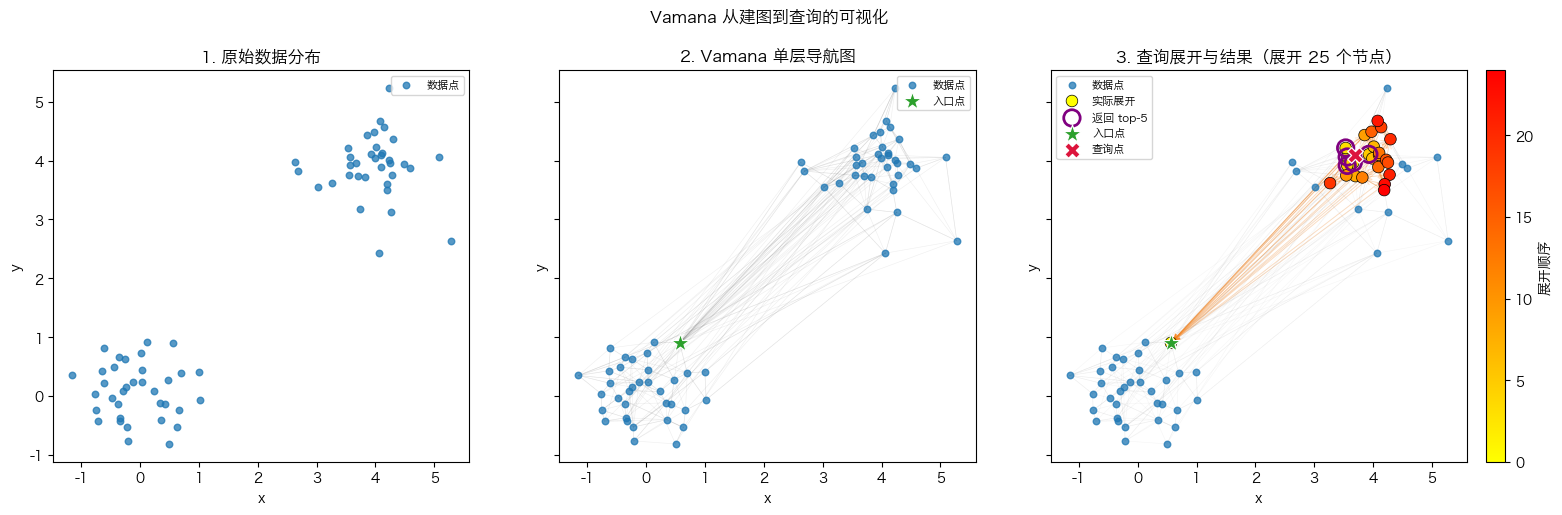

In [4]:
query = np.array([3.7, 4.1])
result, trace = index.search(query, k=5, L_search=24)
expanded = trace["expanded"]
expansion_order = trace["expansion_order"]

print(f"查询点: {query.tolist()}")
print(f"返回 top-5: {result}")
print(f"实际展开节点数: {len(expanded)}")
print(f"展开顺序（前 10 个）: {expansion_order[:10]}")

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)


def draw_points(ax):
    ax.scatter(
        X[:, 0], X[:, 1], s=22, color="tab:blue", alpha=0.75,
        label="数据点", zorder=3,
    )
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal", adjustable="box")


def draw_graph(ax, alpha=0.12):
    for i, neighbors in enumerate(index.graph):
        for j in neighbors:
            ax.plot(
                [X[i, 0], X[j, 0]],
                [X[i, 1], X[j, 1]],
                color="gray", lw=0.45, alpha=alpha, zorder=1,
            )


# 1. 原始数据分布。
draw_points(axes[0])
axes[0].set_title("1. 原始数据分布")
axes[0].legend(fontsize=8)

# 2. 单层图轮廓和入口点。
draw_graph(axes[1])
draw_points(axes[1])
axes[1].scatter(
    *X[index.entry], marker="*", s=190, color="tab:green",
    edgecolors="white", linewidths=0.8, label="入口点", zorder=5,
)
axes[1].set_title("2. Vamana 单层导航图")
axes[1].legend(fontsize=8)

# 3. 查询展开：整图淡化，只强调实际展开子图中的有向边。
draw_graph(axes[2], alpha=0.07)
draw_points(axes[2])
for i in expanded:
    for j in index.graph[i]:
        if j in expanded:
            axes[2].annotate(
                "", xy=X[j], xytext=X[i],
                arrowprops=dict(
                    arrowstyle="->", color="tab:orange", lw=0.7, alpha=0.22
                ),
                zorder=2,
            )
order_ids = np.asarray(expansion_order, dtype=int)
order_scatter = axes[2].scatter(
    X[order_ids, 0],
    X[order_ids, 1],
    c=np.arange(len(order_ids)),
    cmap="autumn_r",
    edgecolors="black",
    linewidths=0.5,
    s=70,
    label="实际展开",
    zorder=4,
)
result_ids = np.asarray(result, dtype=int)
axes[2].scatter(
    X[result_ids, 0],
    X[result_ids, 1],
    facecolors="none",
    edgecolors="purple",
    s=140,
    linewidths=2.0,
    label="返回 top-5",
    zorder=5,
)
axes[2].scatter(
    *X[index.entry],
    marker="*",
    s=190,
    color="tab:green",
    edgecolors="white",
    linewidths=0.8,
    label="入口点",
    zorder=6,
)
axes[2].scatter(
    *query,
    marker="X",
    s=125,
    color="crimson",
    edgecolors="white",
    linewidths=0.9,
    label="查询点",
    zorder=7,
)
axes[2].set_title(f"3. 查询展开与结果（展开 {len(expanded)} 个节点）")
axes[2].legend(fontsize=8, loc="best")
fig.colorbar(
    order_scatter, ax=axes[2], label="展开顺序", fraction=0.046, pad=0.04
)
fig.suptitle("Vamana 从建图到查询的可视化", fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig("../../docs/public/images/Vamana算法结果.png", dpi=100, bbox_inches="tight")
plt.show()




![Vamana 建图与查询结果](../../docs/public/images/Vamana算法结果.png)

### 4.5 参数影响分析

对每个查询，`brute_force` 会逐一比较全部数据，给出最接近的前 `k` 个点。图搜索结果与它的重合比例称为“前 `k` 项召回率”（recall@k）。二维双簇很容易达到召回饱和，因此这里另用固定随机种子生成的 8 维重叠簇，并统计每次搜索实际检查过邻居的点数。

索引只构建一次，然后只改变 `L_search ∈ [5, 8, 16, 32]`，避免把建图差异混进查询参数对比。`L_search` 是列表大小，不是整个搜索检查点数的硬上限；表中的“平均展开”只统计实际检查过邻居的点数，不等于处理器计算时间或固态硬盘读写次数。


In [5]:
def brute_force(X, q, k):
    """全量比较，作为小数据集上的精确基线。"""
    distances = np.linalg.norm(X - q, axis=1)
    return np.argsort(distances)[:k]


def recall_at_k(index, X, queries, k=5, L_search=None):
    scores = []
    for q in queries:
        approximate, _ = index.search(q, k=k, L_search=L_search)
        exact = set(brute_force(X, q, k))
        scores.append(len(set(approximate) & exact) / k)
    return float(np.mean(scores))


# 固定的 8 维重叠簇；构建一次索引，只改变查询预算。
eval_rng = np.random.default_rng(2025)
centers = eval_rng.normal(0, 2.0, size=(4, 8))
X_eval = np.vstack(
    [eval_rng.normal(center, 1.2, size=(40, 8)) for center in centers]
)
queries_eval = np.vstack(
    [eval_rng.normal(center, 1.2, size=(8, 8)) for center in centers]
)
eval_R = 6
eval_index = SimpleVamana(
    R=eval_R, L_build=16, alpha=1.2, L_search=16, seed=7
).fit(X_eval)

budgets = [5, 8, 16, 32]
experiment = []
for budget in budgets:
    score = recall_at_k(
        eval_index, X_eval, queries_eval, k=5, L_search=budget
    )
    expanded_counts = [
        len(eval_index.search(q, k=5, L_search=budget)[1]["expanded"])
        for q in queries_eval
    ]
    mean_expanded = float(np.mean(expanded_counts))
    experiment.append((budget, score, mean_expanded))

print("| L_search | recall@5 | 平均实际展开节点数 | 相比上一档 |")
print("|---:|---:|---:|---|")
previous = None
for budget, score, mean_expanded in experiment:
    if previous is None:
        change = "—"
    else:
        prev_score, prev_expanded = previous
        change = (
            f"召回 {score - prev_score:+.3f}，"
            f"展开 {mean_expanded - prev_expanded:+.2f}"
        )
    print(f"| {budget} | {score:.3f} | {mean_expanded:.2f} | {change} |")
    previous = (score, mean_expanded)


| L_search | recall@5 | 平均实际展开节点数 | 相比上一档 |
|---:|---:|---:|---|
| 5 | 0.806 | 8.69 | — |
| 8 | 0.919 | 12.22 | 召回 +0.113，展开 +3.53 |
| 16 | 0.994 | 20.56 | 召回 +0.075，展开 +8.34 |
| 32 | 1.000 | 35.81 | 召回 +0.006，展开 +15.25 |



实验结果直接列在同一张表中，避免用双纵轴曲线比较两个量纲不同的指标。变化量按未舍入的实验均值计算：

| `L_search` | recall@5 | 平均实际展开节点数 | 相比上一档 |
|---:|---:|---:|---|
| 5 | 0.806 | 8.69 | — |
| 8 | 0.919 | 12.22 | 召回 +0.113，展开 +3.53 |
| 16 | 0.994 | 20.56 | 召回 +0.075，展开 +8.34 |
| 32 | 1.000 | 35.81 | 召回 +0.006，展开 +15.25 |

在这次固定索引的示例中，`L_search` 从 `16` 增至 `32` 时，recall@5 仅增加 `0.006`，平均实际展开节点数增加 `15.25`。

## 5. Vamana 与 DiskANN（磁盘近邻搜索系统）的关系

Vamana 负责先缩小查找范围：它从入口出发，沿图中的连接执行贪心搜索，再用鲁棒裁剪维护连接，把“与全部数据逐一比较”缩小为“只检查一批较有希望的点”；它可以完全在内存中使用，并不以磁盘为前提。

下一篇 [DiskANN 系统](./DiskANN系统.ipynb) 会在这个图导航基础上继续讨论大规模执行：如何在内存和固态硬盘（SSD）之间安排数据，以及如何进行压缩距离估算、缓存和成批读写。存储与执行调度是系统层问题，不是 Vamana 算法定义的一部分。

## 参考资料

- Microsoft Research，NeurIPS 2019： [DiskANN: Fast Accurate Billion-point Nearest Neighbor Search on a Single Node](https://www.microsoft.com/en-us/research/publication/diskann-fast-accurate-billion-point-nearest-neighbor-search-on-a-single-node/)
- 官方实现： [microsoft/DiskANN](https://github.com/microsoft/DiskANN)
